# April 2025 Taxi Demand — Exploratory Analysis

## Objective
Describe daily recorded yellow-taxi pickup patterns across NYC TLC zones.

## Scope
- April 2025 only.
- Validated zone-hour counts.
- Timestamps interpreted as America/New_York under assumption D05.
- Recorded pickups represent served activity, not unmet demand.

## 1. How do total recorded pickups vary across April's days?

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent

assert (ROOT / "pyproject.toml").exists(), "Cannot locate project root."
assert sys.version_info[:3] == (3, 12, 13), "Select the project's Python kernel."

print("Project:", ROOT)
print("Python:", sys.executable)

Project: /Users/neehanth/Documents/PortfolioProjects/Data Science Projects 2026/urban-mobility-demand-forecasting
Python: /Users/neehanth/Documents/PortfolioProjects/Data Science Projects 2026/urban-mobility-demand-forecasting/.venv/bin/python


In [2]:
REPORT_PATH = (ROOT / "reports/data_preparation/april_2025" / "20261106T041153628221Z/report.json")

report = json.loads(REPORT_PATH.read_text())
DATA_PATH = ROOT / report["dataset_path"]

actual_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert actual_hash == report["dataset_sha256"], "Dataset differs from validated snapshot."

df = pd.read_parquet(DATA_PATH)

assert len(df) == report["rows"]
assert not df.duplicated(["pickup_zone_id", "hour_start"]).any()
assert df["pickup_count"].sum() == report["accepted_pickups"]
assert str(df["hour_start"].dt.tz) == "America/New_York"

print(f"Rows: {len(df):,}")
print(f"Recorded pickups: {df['pickup_count'].sum():,}")
df

Rows: 188,640
Recorded pickups: 3,961,082


,pickup_zone_id,hour_start,pickup_count
0,2,2025-04-01 00:00:00-04:00,0
1,2,2025-04-01 01:00:00-04:00,0
2,2,2025-04-01 02:00:00-04:00,0
3,2,2025-04-01 03:00:00-04:00,0
4,2,2025-04-01 04:00:00-04:00,0
...,...,...,...
188635,263,2025-04-30 19:00:00-04:00,120
188636,263,2025-04-30 20:00:00-04:00,123
188637,263,2025-04-30 21:00:00-04:00,142
188638,263,2025-04-30 22:00:00-04:00,91


In [3]:
# Counts across all zones and hours within each NYC-local day
daily_pickups = (
    df.set_index("hour_start")["pickup_count"]
    .resample("D")
    .sum()
    .rename("recorded_pickups")
)

assert len(daily_pickups) == 30
assert daily_pickups.sum() == df["pickup_count"].sum()

daily_pickups

hour_start
2025-04-01 00:00:00-04:00    128611
2025-04-02 00:00:00-04:00    137063
2025-04-03 00:00:00-04:00    138126
2025-04-04 00:00:00-04:00    134807
2025-04-05 00:00:00-04:00    152874
2025-04-06 00:00:00-04:00    122597
2025-04-07 00:00:00-04:00    115568
2025-04-08 00:00:00-04:00    131282
2025-04-09 00:00:00-04:00    137372
2025-04-10 00:00:00-04:00    147308
2025-04-11 00:00:00-04:00    154384
2025-04-12 00:00:00-04:00    149069
2025-04-13 00:00:00-04:00    109458
2025-04-14 00:00:00-04:00     99545
2025-04-15 00:00:00-04:00    121846
2025-04-16 00:00:00-04:00    133639
2025-04-17 00:00:00-04:00    135164
2025-04-18 00:00:00-04:00    125251
2025-04-19 00:00:00-04:00    133725
2025-04-20 00:00:00-04:00    115214
2025-04-21 00:00:00-04:00    107593
2025-04-22 00:00:00-04:00    124546
2025-04-23 00:00:00-04:00    135493
2025-04-24 00:00:00-04:00    148054
2025-04-25 00:00:00-04:00    147290
2025-04-26 00:00:00-04:00    158096
2025-04-27 00:00:00-04:00    141164
2025-04-28 00:00:

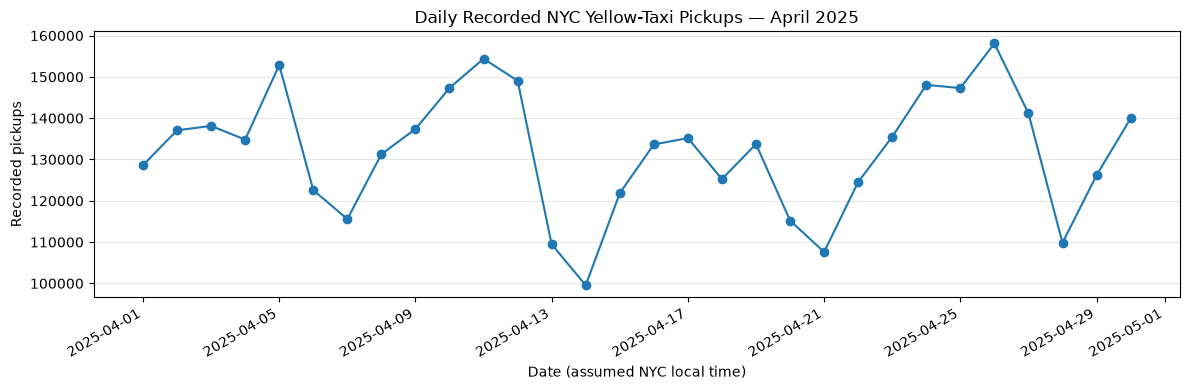

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(daily_pickups.index, daily_pickups.values, marker="o", linewidth=1.5)
ax.set(title="Daily Recorded NYC Yellow-Taxi Pickups — April 2025", xlabel="Date (assumed NYC local time)", ylabel="Recorded pickups")
ax.grid(axis="y", alpha=0.3)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

In [5]:
print("Highest-count day:", daily_pickups.idxmax().date(), " – " , daily_pickups.max(), " pickups")
print("Lowest-count day:", daily_pickups.idxmin().date(), " – " , daily_pickups.min(), " pickups")

Highest-count day: 2025-04-26  –  158096  pickups
Lowest-count day: 2025-04-14  –  99545  pickups


`Observations:` Daily Recorded Pickups — April 2025

**Coverage and totals**
- The prepared dataset contains **188,640 zone-hour observations**
  across 262 NYC taxi zones and 720 hours.
- These observations contain **3,961,082 accepted recorded pickups**,
  averaging approximately **132,036 pickups per day**.

**Highest and lowest days**
- **Saturday, April 26** had the highest daily count: **158,096 pickups**.
- **Monday, April 14** had the lowest daily count: **99,545 pickups**.
- The difference between these days was **58,551 pickups**, showing
  substantial variation within the month.

**Possible weekly pattern**
- Counts generally rise toward the latter part of the week, while
  Mondays are relatively low.
- Every observed Sunday had fewer pickups than the preceding Saturday,
  and every observed Monday had fewer than the preceding Sunday.
- The pattern is not identical each week. For example, Friday,
  April 11 exceeded Saturday, April 12.
- These observations suggest a weekly pattern worth examining through
  day-of-week averages and hourly profiles; they do not yet establish
  stable seasonality.

**Changes worth investigating**
- The decline across April 12–14 ends at the month's lowest count.
- Sunday, April 27 had more pickups than the other observed Sundays.
- These are descriptive findings, not formally detected anomalies.
  Their causes have not been established.

**Limitations**
- One month cannot establish annual seasonality, long-term trends,
  forecast accuracy, or generalization to other periods.
- Citywide daily totals can conceal zone-level and hourly differences.
- Counts represent recorded served pickups, not total requests,
  unmet demand, or available vehicle capacity.
- Dates follow the project's assumed America/New_York interpretation.
- No changes are attributed to weather, events, or holidays without
  additional evidence.

## 2. How do hourly pickup patterns differ between weekdays and weekends?

Compare average citywide recorded pickups at each local clock hour.

First sum across zones for each dated hour, then average those hourly
totals separately for weekdays and weekends. This avoids comparing raw
totals across unequal numbers of days.

Weekday means Monday–Friday; it does not exclude holidays.

In [6]:
# Calculate citywide hourly totals
hourly_city = (
    df.groupby("hour_start", as_index=False)["pickup_count"]
    .sum()
    .sort_values("hour_start")
)

hourly_city["date"] = hourly_city["hour_start"].dt.date
hourly_city["hour"] = hourly_city["hour_start"].dt.hour
hourly_city["day_type"] = (
    hourly_city["hour_start"].dt.dayofweek
    .map(lambda day: "Weekend" if day >= 5 else "Weekday")
)

assert len(hourly_city) == 720
assert hourly_city["pickup_count"].sum() == df["pickup_count"].sum()

day_counts = hourly_city.groupby("day_type")["date"].nunique()
day_counts

/var/folders/1y/fqrnl1wj2v32zp3hwv5ny6_r0000gn/T/ipykernel_81104/2031575342.py:11: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  hourly_city["hour_start"].dt.dayofweek


day_type
Weekday    22
Weekend     8
Name: date, dtype: int64

In [7]:
# Calculate the average hourly profiles
hourly_profile = (
    hourly_city.groupby(["day_type", "hour"])["pickup_count"]
    .agg(mean_pickups="mean", median_pickups="median", days="size")
    .reset_index()
)

assert len(hourly_profile) == 48
assert hourly_profile["days"].eq(hourly_profile["day_type"].map(day_counts)).all()

hourly_profile

,day_type,hour,mean_pickups,median_pickups,days
0,Weekday,0,2264.045455,1940.5,22
1,Weekday,1,1048.454545,857.0,22
2,Weekday,2,592.636364,437.0,22
3,Weekday,3,414.181818,324.5,22
4,Weekday,4,516.090909,482.5,22
5,Weekday,5,996.181818,977.5,22
6,Weekday,6,2288.909091,2304.5,22
7,Weekday,7,4683.136364,4920.5,22
8,Weekday,8,6228.045455,6397.5,22
9,Weekday,9,6108.227273,6256.0,22


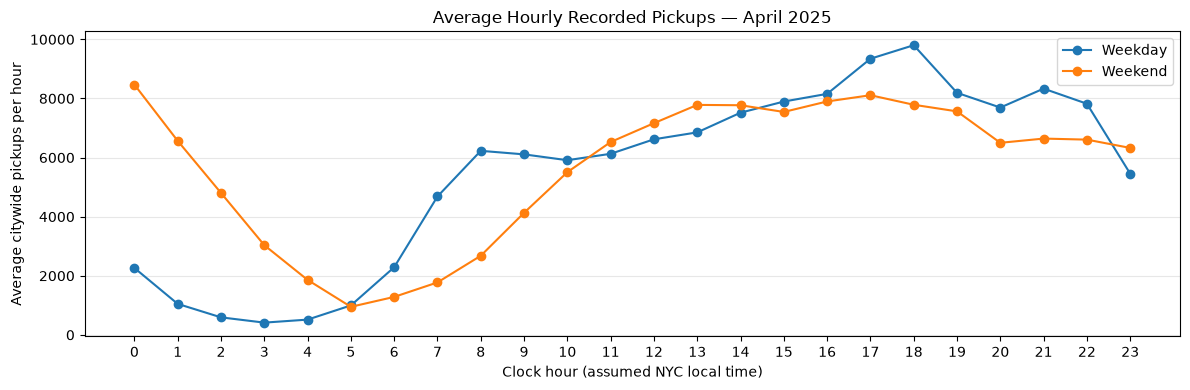

In [ ]:
# Plot Average Hourly Recorded Pickups
profiles = hourly_profile.pivot(index="hour", columns="day_type", values="mean_pickups")

fig, ax = plt.subplots(figsize=(12, 4))
for day_type in ["Weekday", "Weekend"]:
    ax.plot(profiles.index, profiles[day_type], marker="o", label=day_type)

ax.set(
    title="Average Hourly Recorded Pickups — April 2025",
    xlabel="Clock hour (assumed NYC local time)",
    ylabel="Average citywide pickups per hour",
)
ax.set_xticks(range(24))
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

In [9]:
# Identify each profile’s peak
peak_rows = hourly_profile.loc[
    hourly_profile.groupby("day_type")["mean_pickups"].idxmax(),
    ["day_type", "hour", "mean_pickups", "days"],
]

peak_rows

,day_type,hour,mean_pickups,days
18,Weekday,18,9802.409091,22
24,Weekend,0,8468.375000,8


`Observations:` Weekday versus Weekend Hourly Pickups

**Comparison basis**
- Profiles show average citywide recorded pickups per clock hour.
- Each weekday average uses **22 days**; each weekend average uses **8 days**. Averaging avoids comparing totals across unequal day counts.

**Peak timing**
- The weekday profile peaks during **18:00–19:00**, averaging approximately **9,802 pickups**.
- The weekend profile peaks during **00:00–01:00**, averaging approximately **8,468 pickups**.
- Weekend activity also remains relatively high throughout the afternoon and early evening, but below its midnight maximum.

**Differences across the day**
- Weekend averages exceed weekday averages from **00:00 through 04:00**.
- Weekday activity rises earlier in the morning. At **08:00**, weekdays average approximately **6,228 pickups**, compared with **2,677** on weekends.
- Weekend averages exceed weekday averages from **11:00 through 14:00**.
- Weekday averages are higher from **15:00 through 22:00**, with a pronounced early-evening peak.
- At **23:00**, the weekend average again exceeds the weekday average.
- The lowest average occurs at **03:00 on weekdays**—approximately **414 pickups**—and **05:00 on weekends**—approximately **949 pickups**.

**Interpretation**
- Pickup timing differs between the two calendar-day groups; their profiles are not simply identical curves at different volume levels.
- These differences motivate testing hour-of-day, day-of-week, and seasonal-baseline features during modeling. Their predictive value has not yet been evaluated.

<!-- **Limitations**
- Weekend averages combine Saturdays and Sundays, potentially concealing differences between them. Weekday averages also combine five distinct days.
- Day groups follow the calendar: Saturday at 00:00 is classified as weekend, while Friday at 23:00 is classified as weekday.
- The eight observed weekend days provide limited evidence about stability across other months.
- Mean profiles conceal day-to-day variability and geographic differences.
- No causes—such as commuting, nightlife, weather, or events—have been established by this comparison.
- Counts represent recorded served pickups under the assumed NYC-local timestamp interpretation, not unmet demand or available capacity. -->